# Fase 4: Análisis exploratorio (EDA)

**Startup:** NaitPrais · **Cliente:** Tabaiba Stays (gestora ficticia de 60 viviendas vacacionales)

Objetivo: entender qué está pasando realmente en la empresa antes de construir una solución.

**Datos**
- `viviendas`, `reservas`, `calendario_precios`: datos **simulados** del cliente (enero 2024 - agosto 2026).
- `mercado_istac`: datos **reales** del ISTAC por municipio y mes (enero 2019 - julio 2026).

**Índice**
1. Carga de datos
2. Limpieza y preparación
3. Estadísticas generales
4. ¿Cuándo se llena y cuánto se cobra?
5. El calendario de tarifas frente al mercado real
6. Fechas especiales
7. Tamaño de la vivienda y temporada
8. Tabaiba Stays frente al mercado de su municipio
9. Evolución del mercado real (2019-2026)
10. Relaciones entre variables
11. Segmentación de viviendas
12. Huéspedes, canales y reseñas
13. Anomalías
14. Conclusiones

## 1. Carga de datos

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

RUTA_DB = Path("../data/naitprais.db")
RUTA_FIGURAS = Path("../docs/img")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Estilo de los gráficos con los colores de NaitPrais
AZUL = "#103A5C"
ROSA = "#B3336B"
AZUL_CLARO = "#8FB3D1"
GRIS = "#9A958F"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
})
pd.set_option("display.float_format", "{:,.2f}".format)


def guardar(nombre):
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS / nombre, dpi=130, bbox_inches="tight")
    plt.show()


con = sqlite3.connect(RUTA_DB)
municipios = pd.read_sql("SELECT * FROM municipios", con)
viviendas = pd.read_sql("SELECT * FROM viviendas", con)
reservas = pd.read_sql("SELECT * FROM reservas", con)
calendario = pd.read_sql("SELECT * FROM calendario_precios", con)
mercado = pd.read_sql("SELECT * FROM mercado_istac", con)

for nombre, tabla in [("municipios", municipios), ("viviendas", viviendas),
                      ("reservas", reservas), ("calendario", calendario), ("mercado", mercado)]:
    print(f"{nombre:<12} {tabla.shape}")

municipios   (5, 4)
viviendas    (64, 9)
reservas     (5331, 12)
calendario   (59930, 4)
mercado      (455, 8)


## 2. Limpieza y preparación

Revisamos tipos de datos, valores vacíos, duplicados y valores fuera de rango. Después creamos las columnas que necesitamos para el análisis.

In [2]:
# Fechas: en SQLite se guardan como texto, las pasamos a fecha
for col in ["fecha_reserva", "fecha_entrada", "fecha_salida"]:
    reservas[col] = pd.to_datetime(reservas[col])
calendario["fecha"] = pd.to_datetime(calendario["fecha"])

# Valores vacíos
print("Vacíos en reservas:")
print(reservas.isna().sum()[reservas.isna().sum() > 0])
print("\nVacíos en mercado_istac:", mercado.isna().sum().sum())

# Duplicados
print("\nReservas duplicadas:", reservas.duplicated(subset=["id_vivienda", "fecha_entrada", "estado"]).sum())
print("Días duplicados en el calendario:", calendario.duplicated(subset=["id_vivienda", "fecha"]).sum())

# Rangos
print("\nPrecios <= 0:", (calendario["precio_noche"] <= 0).sum())
print("Noches que no cuadran con las fechas:",
      (reservas["noches"] != (reservas["fecha_salida"] - reservas["fecha_entrada"]).dt.days).sum())
print("Reservas hechas después de la llegada:", (reservas["fecha_reserva"] > reservas["fecha_entrada"]).sum())

Vacíos en reservas:
puntuacion    2259
dtype: int64

Vacíos en mercado_istac: 0

Reservas duplicadas: 0
Días duplicados en el calendario: 0

Precios <= 0: 0
Noches que no cuadran con las fechas: 0
Reservas hechas después de la llegada: 0


**Resultado de la limpieza**

- El único campo con vacíos es `puntuacion`, y es normal: son las reservas en las que el huésped no dejó reseña. No se rellena; se analiza solo sobre las reservas con reseña.
- No hay duplicados ni valores fuera de rango.
- **Cancelaciones:** se quedan en la tabla, pero se excluyen al calcular ocupación, ingresos y estancia media.
- **2026 es un año incompleto** (el cliente llega a agosto y el ISTAC a julio). Para comparar años usamos los mismos meses.
- **ISTAC:** no publica la ocupación por noches (solo el % de viviendas con alguna reserva), así que comparamos con el mercado usando los **ingresos por vivienda disponible**. En Mogán hay menos de 100 viviendas vacacionales, así que sus cifras varían mucho de un mes a otro.

In [3]:
# Columnas nuevas para el análisis
TARIFAS = {11: "alta", 12: "alta", 1: "alta", 2: "alta", 3: "alta", 4: "alta",
           7: "media", 8: "media", 5: "baja", 6: "baja", 9: "baja", 10: "baja"}

EVENTOS = [  # Navidad, Carnaval y Semana Santa
    ("2023-12-20", "2024-01-06"), ("2024-02-08", "2024-02-18"), ("2024-03-23", "2024-03-31"),
    ("2024-12-20", "2025-01-06"), ("2025-02-27", "2025-03-09"), ("2025-04-12", "2025-04-20"),
    ("2025-12-20", "2026-01-06"), ("2026-02-12", "2026-02-22"), ("2026-03-28", "2026-04-05"),
]


def es_evento(fechas):
    marca = pd.Series(False, index=fechas.index)
    for inicio, fin in EVENTOS:
        marca |= fechas.between(inicio, fin)
    return marca


viviendas = viviendas.merge(municipios[["id_municipio", "nombre", "isla"]], on="id_municipio")
viviendas = viviendas.rename(columns={"nombre": "municipio"})
viviendas["tamano"] = pd.cut(viviendas["plazas"], bins=[0, 3, 5, 16],
                             labels=["Pequeña (2-3)", "Mediana (4-5)", "Grande (6-8)"])

calendario = calendario.merge(viviendas[["id_vivienda", "municipio", "tipo", "plazas", "tamano"]], on="id_vivienda")
calendario["anio"] = calendario["fecha"].dt.year
calendario["mes"] = calendario["fecha"].dt.month
calendario["periodo"] = calendario["fecha"].dt.strftime("%Y-%m")
calendario["tarifa"] = calendario["mes"].map(TARIFAS)
calendario["evento"] = es_evento(calendario["fecha"])
calendario["ingreso"] = calendario["precio_noche"] * calendario["ocupada"]

reservas = reservas.merge(viviendas[["id_vivienda", "municipio", "plazas", "tamano"]], on="id_vivienda")
reservas["antelacion"] = (reservas["fecha_entrada"] - reservas["fecha_reserva"]).dt.days
reservas["mes"] = reservas["fecha_entrada"].dt.month
reservas["tarifa"] = reservas["mes"].map(TARIFAS)
reservas["evento"] = es_evento(reservas["fecha_entrada"])
confirmadas = reservas[reservas["estado"] == "confirmada"].copy()

mercado = mercado.merge(municipios[["id_municipio", "nombre"]], on="id_municipio").rename(columns={"nombre": "municipio"})
mercado["anio"] = mercado["periodo"].str[:4].astype(int)
mercado["mes"] = mercado["periodo"].str[5:].astype(int)
mercado["ingresos_por_vivienda"] = mercado["ingresos"] / mercado["viviendas_disponibles"]

print("Preparado:", calendario.shape, confirmadas.shape, mercado.shape)

Preparado: (59930, 14) (4972, 19) (455, 12)


## 3. Estadísticas generales

In [4]:
resumen = pd.DataFrame({
    "viviendas": calendario.groupby("anio")["id_vivienda"].nunique(),
    "reservas_confirmadas": confirmadas.groupby(confirmadas["fecha_entrada"].dt.year).size(),
    "ocupacion_%": calendario.groupby("anio")["ocupada"].mean() * 100,
    "precio_medio_€": calendario.groupby("anio")["precio_noche"].mean(),
    "ingresos_€": calendario.groupby("anio")["ingreso"].sum(),
    "estancia_media": confirmadas.groupby(confirmadas["fecha_entrada"].dt.year)["noches"].mean(),
    "antelacion_media_dias": confirmadas.groupby(confirmadas["fecha_entrada"].dt.year)["antelacion"].mean(),
})
resumen

,viviendas,reservas_confirmadas,ocupacion_%,precio_medio_€,ingresos_€,estancia_media,antelacion_media_dias
2024,64,1878,67.63,96.84,"1,500,450.00",8.39,30.92
2025,64,1935,71.38,99.90,"1,598,480.00",8.30,32.54
2026,60,1159,69.63,102.82,"1,040,845.00",8.50,32.65


In [5]:
print("Tasa de cancelación:", round((reservas["estado"] == "cancelada").mean() * 100, 1), "%")
print("Reservas con reseña:", round(confirmadas["puntuacion"].notna().mean() * 100, 1), "%")
confirmadas[["noches", "num_huespedes", "precio_noche", "antelacion", "puntuacion"]].describe()

Tasa de cancelación: 6.7 %
Reservas con reseña: 61.8 %


,noches,num_huespedes,precio_noche,antelacion,puntuacion
count,"4,972.00","4,972.00","4,972.00","4,972.00","3,072.00"
mean,8.38,3.00,98.39,31.95,4.45
std,3.04,1.47,47.40,36.28,0.82
min,2.00,1.00,45.00,0.00,1.00
25%,6.00,2.00,70.00,8.00,4.00
50%,8.00,3.00,88.94,20.00,5.00
75%,10.00,4.00,105.00,44.00,5.00
max,21.00,8.00,290.00,365.00,5.00


## 4. ¿Cuándo se llena y cuánto se cobra?

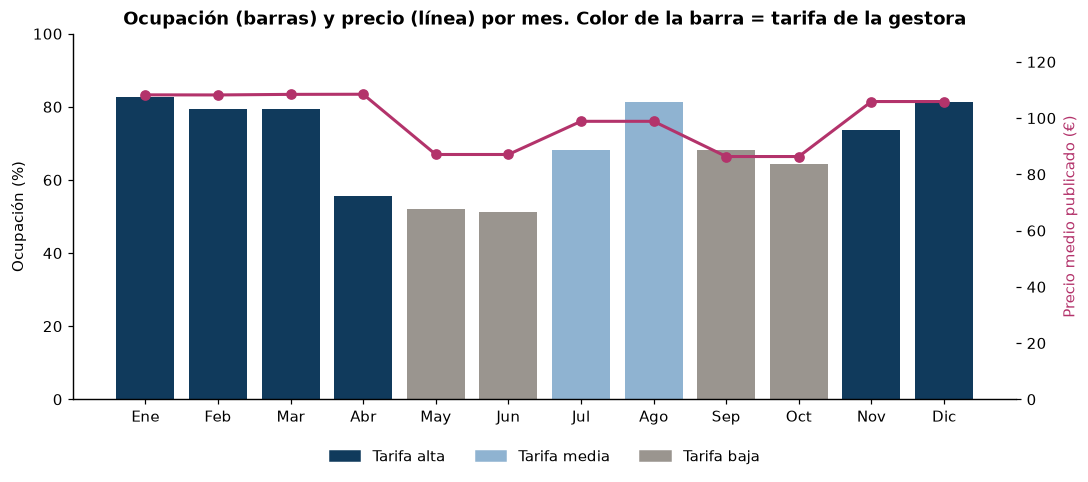

,ocupacion,precio,tarifa
mes,,,
1,0.83,108.26,alta
2,0.79,108.23,alta
3,0.79,108.43,alta
4,0.56,108.48,alta
5,0.52,87.05,baja
6,0.51,87.05,baja
7,0.68,98.85,media
8,0.81,98.85,media
9,0.68,86.33,baja


In [6]:
por_mes = calendario.groupby("mes").agg(ocupacion=("ocupada", "mean"), precio=("precio_noche", "mean"))
colores = por_mes.index.map(TARIFAS).map({"alta": AZUL, "media": AZUL_CLARO, "baja": GRIS})
nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(nombres_mes, por_mes["ocupacion"] * 100, color=colores)
ax.set_ylabel("Ocupación (%)")
ax.set_ylim(0, 100)
ax2 = ax.twinx()
ax2.plot(nombres_mes, por_mes["precio"], color=ROSA, marker="o", linewidth=2)
ax2.set_ylabel("Precio medio publicado (€)", color=ROSA)
ax2.set_ylim(0, 130)
ax2.spines["top"].set_visible(False)
ax.set_title("Ocupación (barras) y precio (línea) por mes. Color de la barra = tarifa de la gestora")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Tarifa alta"), Patch(color=AZUL_CLARO, label="Tarifa media"),
                   Patch(color=GRIS, label="Tarifa baja")], loc="upper center",
          bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
guardar("eda_01_ocupacion_precio_mes.png")
por_mes.assign(tarifa=por_mes.index.map(TARIFAS))

**Qué vemos**
- El precio solo tiene 3 escalones, pero la ocupación cambia mucho más de un mes a otro.
- **Abril** se cobra como enero (tarifa alta), pero se ocupa como mayo.
- **Agosto** se ocupa como diciembre, pero se cobra con la tarifa media.

## 5. El calendario de tarifas frente al mercado real

¿Pasa lo mismo en el mercado real? Usamos los ingresos por vivienda del ISTAC (media 2023-2025 de los 5 municipios) como indicador de demanda y lo comparamos con el nivel de precio que aplica la gestora cada mes. Los dos se expresan como índice (media del año = 100).

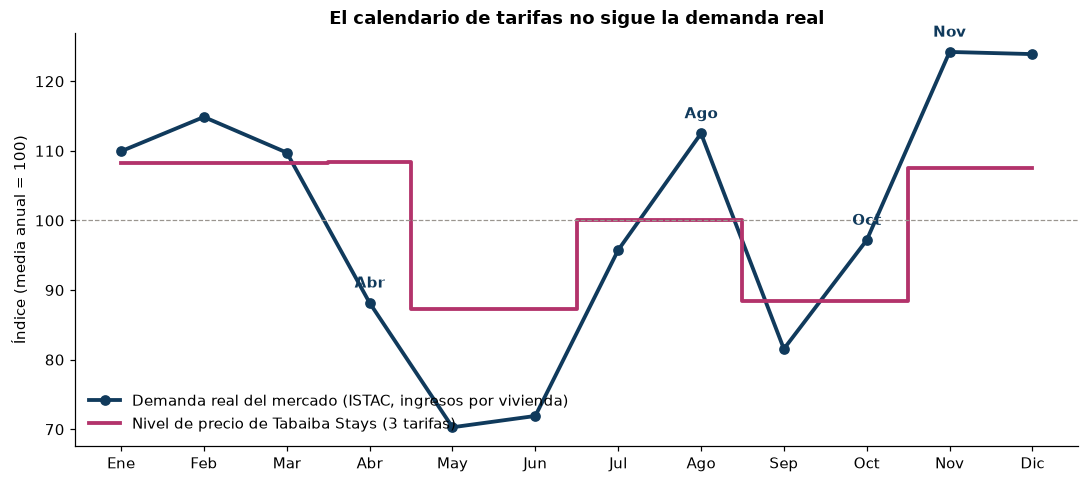

,mercado_real,precio_gestora,tarifa
Ene,110.00,108.00,alta
Feb,115.00,108.00,alta
Mar,110.00,108.00,alta
Abr,88.00,108.00,alta
May,70.00,87.00,baja
Jun,72.00,87.00,baja
Jul,96.00,100.00,media
Ago,112.00,100.00,media
Sep,82.00,88.00,baja
Oct,97.00,88.00,baja


In [7]:
real = mercado[mercado["anio"].between(2023, 2025)].groupby("mes")["ingresos_por_vivienda"].mean()
indice_mercado = real / real.mean() * 100

precio_gestora = calendario[calendario["anio"] == 2025].groupby("mes")["precio_noche"].mean()
indice_gestora = precio_gestora / precio_gestora.mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(nombres_mes, indice_mercado.values, color=AZUL, marker="o", linewidth=2.5,
        label="Demanda real del mercado (ISTAC, ingresos por vivienda)")
ax.step(nombres_mes, indice_gestora.values, where="mid", color=ROSA, linewidth=2.5,
        label="Nivel de precio de Tabaiba Stays (3 tarifas)")
ax.axhline(100, color=GRIS, linewidth=0.8, linestyle="--")
ax.set_ylabel("Índice (media anual = 100)")
ax.set_title("El calendario de tarifas no sigue la demanda real")
ax.legend(frameon=False, loc="lower left")
for mes in ["Abr", "Ago", "Oct", "Nov"]:
    i = nombres_mes.index(mes)
    ax.annotate(mes, (i, indice_mercado.values[i]), textcoords="offset points", xytext=(0, 10),
                ha="center", color=AZUL, fontweight="bold")
guardar("eda_02_tarifas_vs_mercado.png")

pd.DataFrame({"mercado_real": indice_mercado.round(0).values,
              "precio_gestora": indice_gestora.round(0).values,
              "tarifa": [TARIFAS[m] for m in range(1, 13)]}, index=nombres_mes)

**Descubrimiento con datos reales**

Según el ISTAC (índice 100 = mes medio), en estos municipios:
- **Abril** (88) es mucho más flojo que marzo (110), pero la gestora lo cobra como temporada alta (108).
- **Agosto** (112) está al nivel de enero y febrero, pero se cobra con la tarifa media (100).
- **Octubre** (97) se parece a julio, pero se cobra como temporada baja (88).
- **Noviembre y diciembre** (124) son los meses más fuertes del año y se cobran igual que abril.
- **Mayo y junio** (70-72) son más flojos que el precio que se les pone (87).

Es decir, el problema no es solo la temporada baja: **el calendario de tarifas está mal repartido**.

## 6. Fechas especiales (Navidad, Carnaval y Semana Santa)

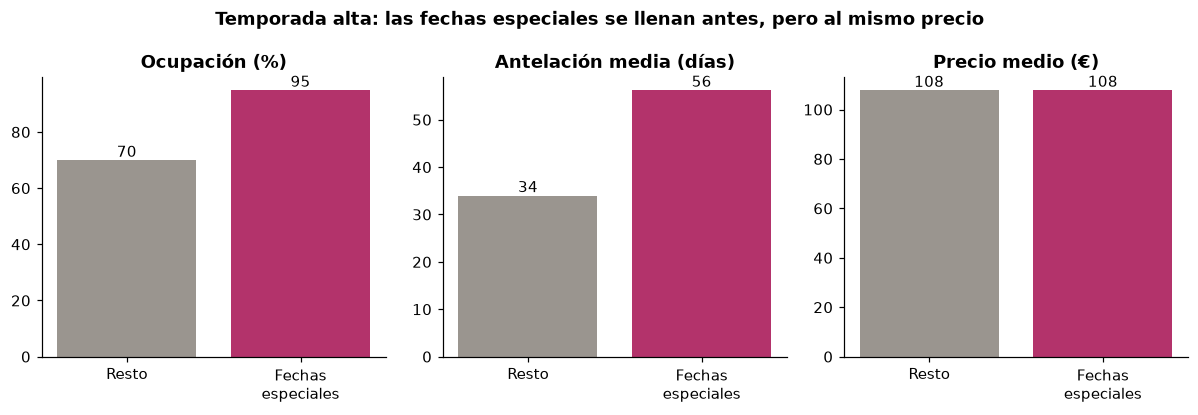

,ocupacion,precio,mean,median
Resto de la temporada alta,0.70,107.72,33.95,23.00
Fechas especiales,0.95,107.76,56.19,42.00


In [8]:
alta = calendario[calendario["tarifa"] == "alta"]
ev = alta.groupby("evento").agg(ocupacion=("ocupada", "mean"), precio=("precio_noche", "mean"))
antelacion = confirmadas[confirmadas["tarifa"] == "alta"].groupby("evento")["antelacion"].agg(["mean", "median"])
tabla_eventos = ev.join(antelacion)
tabla_eventos.index = ["Resto de la temporada alta", "Fechas especiales"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
etiquetas = ["Resto", "Fechas\nespeciales"]
axes[0].bar(etiquetas, tabla_eventos["ocupacion"] * 100, color=[GRIS, ROSA])
axes[0].set_title("Ocupación (%)")
axes[1].bar(etiquetas, tabla_eventos["mean"], color=[GRIS, ROSA])
axes[1].set_title("Antelación media (días)")
axes[2].bar(etiquetas, tabla_eventos["precio"], color=[GRIS, ROSA])
axes[2].set_title("Precio medio (€)")
for a in axes:
    for p in a.patches:
        a.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")
fig.suptitle("Temporada alta: las fechas especiales se llenan antes, pero al mismo precio", fontweight="bold")
guardar("eda_03_fechas_especiales.png")
tabla_eventos

**Qué vemos:** en las fechas especiales la ocupación es casi total y las reservas llegan con casi el doble de antelación, pero el precio es exactamente el mismo. Cuando una fecha se vende tan pronto, es señal de que el precio es bajo.

## 7. Tamaño de la vivienda y temporada

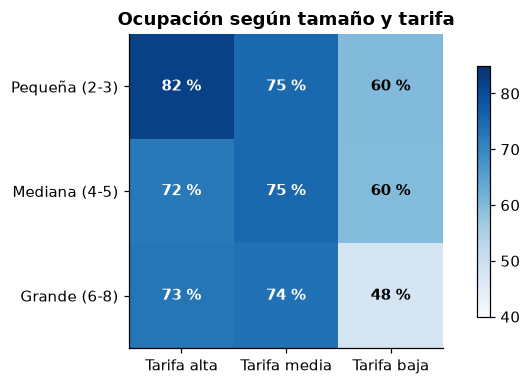

tarifa,alta,media,baja
tamano,,,
Pequeña (2-3),81.85,75.03,59.93
Mediana (4-5),72.23,75.05,59.76
Grande (6-8),72.93,73.69,47.85


In [9]:
tabla_tamano = calendario.pivot_table(index="tamano", columns="tarifa", values="ocupada", observed=True)[["alta", "media", "baja"]] * 100

fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(tabla_tamano.values, cmap="Blues", vmin=40, vmax=85)
ax.set_xticks(range(3), ["Tarifa alta", "Tarifa media", "Tarifa baja"])
ax.set_yticks(range(3), tabla_tamano.index)
for i in range(3):
    for j in range(3):
        valor = tabla_tamano.values[i, j]
        ax.text(j, i, f"{valor:.0f} %", ha="center", va="center",
                color="white" if valor > 68 else "black", fontweight="bold")
ax.set_title("Ocupación según tamaño y tarifa")
fig.colorbar(im, ax=ax, shrink=0.8)
guardar("eda_04_tamano_temporada.png")
tabla_tamano

**Qué vemos:** las viviendas grandes (6-8 plazas) caen por debajo del 50 % en temporada baja, mientras que las pequeñas mantienen un 60 %. Las pequeñas son las que más se llenan en temporada alta.

## 8. Tabaiba Stays frente al mercado de su municipio

Comparamos los ingresos medios por vivienda al mes en 2025. Es una comparación orientativa: el mercado incluye viviendas de todos los tamaños y no sabemos si sus ingresos incluyen la limpieza.

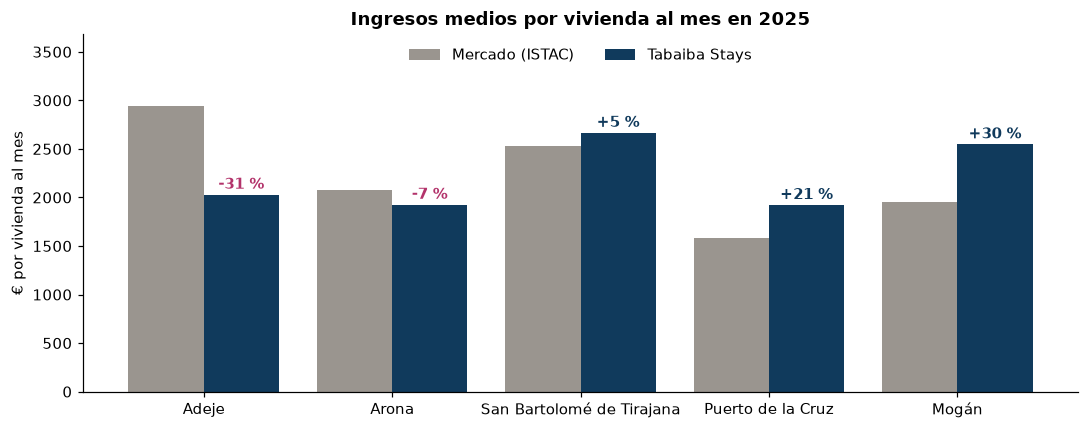

,gestora,ingresos_por_vivienda,diferencia_%,viviendas_gestora
municipio,,,,
Adeje,"2,027.33","2,945.67",-31.18,20
Arona,"1,923.51","2,077.53",-7.41,16
San Bartolomé de Tirajana,"2,664.49","2,532.51",5.21,10
Puerto de la Cruz,"1,921.30","1,584.80",21.23,8
Mogán,"2,546.11","1,955.92",30.17,6


In [10]:
gestora_mes = (calendario.groupby(["municipio", "periodo", "id_vivienda"])["ingreso"].sum()
               .groupby(["municipio", "periodo"]).mean().rename("gestora").reset_index())
comparacion = gestora_mes.merge(mercado[["municipio", "periodo", "ingresos_por_vivienda"]], on=["municipio", "periodo"])
c2025 = comparacion[comparacion["periodo"].str.startswith("2025")].groupby("municipio")[["gestora", "ingresos_por_vivienda"]].mean()
c2025["diferencia_%"] = (c2025["gestora"] / c2025["ingresos_por_vivienda"] - 1) * 100
c2025["viviendas_gestora"] = viviendas[viviendas["activa"] == 1].groupby("municipio").size()
c2025 = c2025.sort_values("diferencia_%")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(c2025))
ax.bar(x - 0.2, c2025["ingresos_por_vivienda"], width=0.4, color=GRIS, label="Mercado (ISTAC)")
ax.bar(x + 0.2, c2025["gestora"], width=0.4, color=AZUL, label="Tabaiba Stays")
for i, d in enumerate(c2025["diferencia_%"]):
    ax.annotate(f"{d:+.0f} %", (i + 0.2, c2025["gestora"].iloc[i]), textcoords="offset points",
                xytext=(0, 4), ha="center", color=ROSA if d < 0 else AZUL, fontweight="bold")
ax.set_xticks(x, c2025.index)
ax.set_ylim(0, c2025[["gestora", "ingresos_por_vivienda"]].max().max() * 1.25)
ax.set_ylabel("€ por vivienda al mes")
ax.set_title("Ingresos medios por vivienda al mes en 2025")
ax.legend(frameon=False, loc="upper center", ncol=2)
guardar("eda_05_gestora_vs_mercado.png")
c2025

**Descubrimiento:** en **Adeje**, donde la gestora tiene más viviendas (20 activas), cada vivienda ingresa alrededor de un **30 % menos** que la media del municipio. Adeje es el mercado más caro de los cinco, y la gestora lo trata casi como Arona. En Puerto de la Cruz y Mogán, en cambio, está por encima del mercado (en Mogán el mercado tiene menos de 100 viviendas, así que la cifra es poco estable).

## 9. Evolución del mercado real (2019-2026)

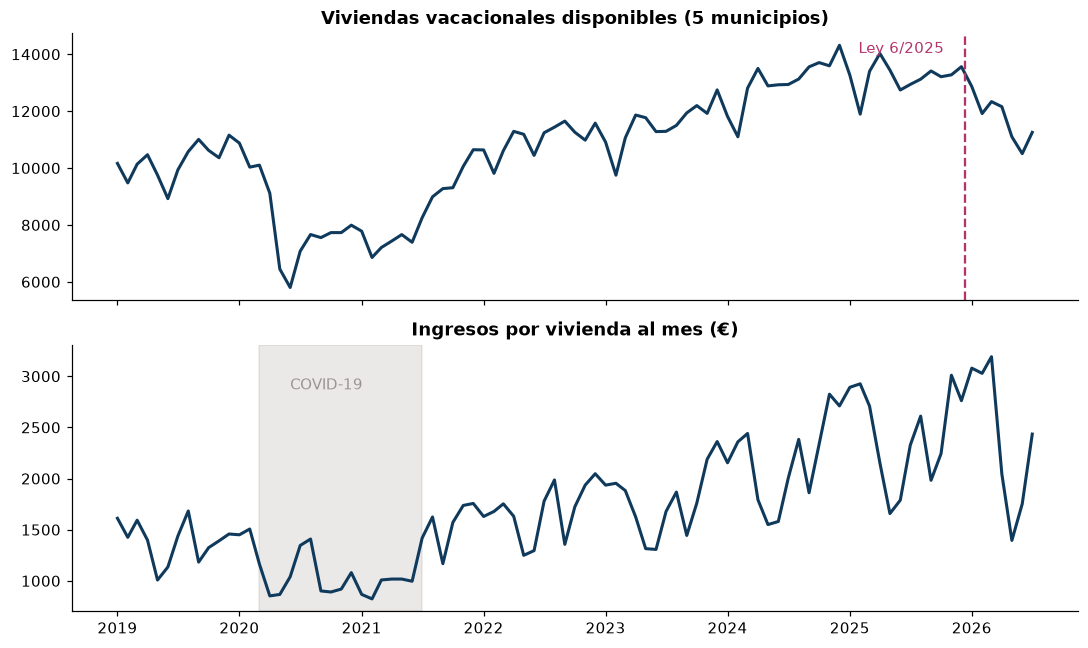

Cambio enero-julio 2026 frente a 2025 (%):
viviendas_disponibles   -10.40
ingresos                 -6.30
ingresos_por_vivienda     4.60
dtype: float64

Viviendas disponibles, cambio mensual 2026 frente a 2025 (%):
mes
1    -3.00
2     0.20
3    -7.90
4   -13.30
5   -17.40
6   -17.60
7   -13.00
dtype: float64


In [11]:
total = mercado.groupby("periodo").agg(viviendas=("viviendas_disponibles", "sum"), ingresos=("ingresos", "sum"))
total["ingresos_por_vivienda"] = total["ingresos"] / total["viviendas"]
total.index = pd.to_datetime(total.index)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(total.index, total["viviendas"], color=AZUL, linewidth=2)
axes[0].set_title("Viviendas vacacionales disponibles (5 municipios)")
axes[0].axvline(pd.Timestamp("2025-12-13"), color=ROSA, linestyle="--")
axes[0].annotate("Ley 6/2025", (pd.Timestamp("2025-12-13"), total["viviendas"].max()), color=ROSA,
                 xytext=(-70, -5), textcoords="offset points")
axes[1].plot(total.index, total["ingresos_por_vivienda"], color=AZUL, linewidth=2)
axes[1].set_title("Ingresos por vivienda al mes (€)")
axes[1].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-30"), color=GRIS, alpha=0.2)
axes[1].annotate("COVID-19", (pd.Timestamp("2020-06-01"), total["ingresos_por_vivienda"].max() * 0.9), color=GRIS)
guardar("eda_06_mercado_historico.png")

# Comparación enero-julio 2026 frente a enero-julio 2025
ene_jul = mercado[mercado["mes"] <= 7].groupby("anio")[["viviendas_disponibles", "ingresos"]].sum()
ene_jul["ingresos_por_vivienda"] = ene_jul["ingresos"] / ene_jul["viviendas_disponibles"]
cambio = (ene_jul.loc[2026] / ene_jul.loc[2025] - 1) * 100
print("Cambio enero-julio 2026 frente a 2025 (%):")
print(cambio.round(1))

por_mes_2026 = mercado[mercado["anio"].isin([2025, 2026]) & (mercado["mes"] <= 7)].pivot_table(
    index="mes", columns="anio", values="viviendas_disponibles", aggfunc="sum")
print("\nViviendas disponibles, cambio mensual 2026 frente a 2025 (%):")
print(((por_mes_2026[2026] / por_mes_2026[2025] - 1) * 100).round(1))

**Descubrimiento con datos reales**

- Tras la pandemia, los ingresos por vivienda no han dejado de crecer.
- **Desde abril de 2026 hay entre un 13 % y un 18 % menos de viviendas disponibles** que un año antes, coincidiendo con la entrada en vigor de la Ley 6/2025 (diciembre de 2025). No podemos afirmar que la ley sea la única causa, pero el cambio es claro.
- Aun así, **los ingresos por vivienda han subido** en enero-julio de 2026. Menos oferta y demanda estable: hay margen para cobrar más, no menos.

## 10. Relaciones entre variables

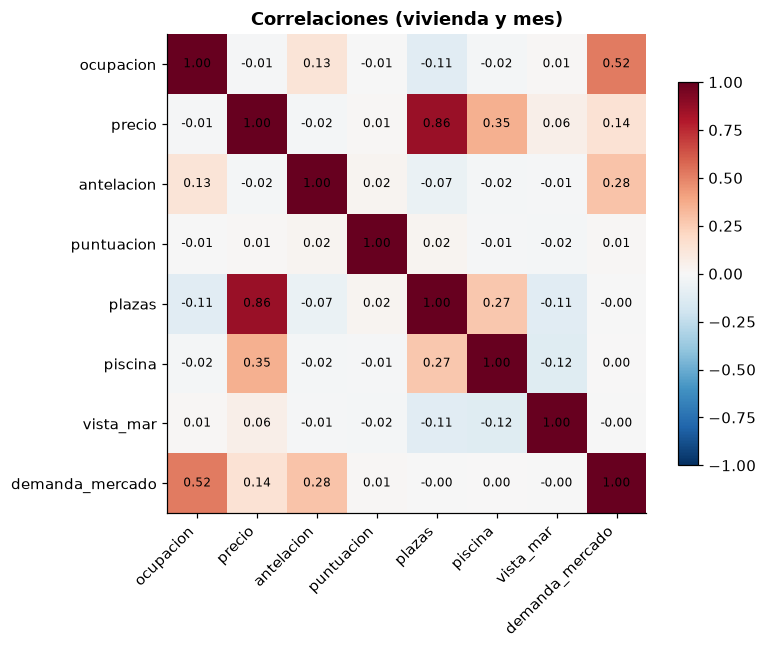

plazas            -0.11
piscina           -0.02
precio            -0.01
puntuacion        -0.01
vista_mar          0.01
antelacion         0.13
demanda_mercado    0.52
ocupacion          1.00
Name: ocupacion, dtype: float64

In [12]:
# Una fila por vivienda y mes
vm = calendario.groupby(["id_vivienda", "periodo"]).agg(
    ocupacion=("ocupada", "mean"), precio=("precio_noche", "mean"), mes=("mes", "first")).reset_index()
antel_vm = confirmadas.assign(periodo=confirmadas["fecha_entrada"].dt.strftime("%Y-%m")).groupby(
    ["id_vivienda", "periodo"]).agg(antelacion=("antelacion", "mean"), puntuacion=("puntuacion", "mean"))
vm = vm.merge(antel_vm, on=["id_vivienda", "periodo"], how="left")
vm = vm.merge(viviendas[["id_vivienda", "plazas", "piscina", "vista_mar"]], on="id_vivienda")
vm["demanda_mercado"] = vm["mes"].map(indice_mercado)

variables = ["ocupacion", "precio", "antelacion", "puntuacion", "plazas", "piscina", "vista_mar", "demanda_mercado"]
correlaciones = vm[variables].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(correlaciones, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)), variables, rotation=45, ha="right")
ax.set_yticks(range(len(variables)), variables)
for i in range(len(variables)):
    for j in range(len(variables)):
        ax.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlaciones (vivienda y mes)")
fig.colorbar(im, ax=ax, shrink=0.8)
guardar("eda_07_correlaciones.png")
correlaciones["ocupacion"].sort_values()

**Qué vemos**
- La ocupación sube sobre todo con la **demanda real del mercado** (correlación de 0,52) y algo con la antelación: los meses que más se llenan se reservan antes.
- El precio casi no se relaciona con la ocupación, y eso **no significa que el precio no importe**. La gestora casi no cambia sus precios (3 tarifas al año), y el precio depende sobre todo del tamaño de la vivienda. Con tan poca variación, los datos no permiten medir bien el efecto del precio. Lo tendremos en cuenta en la solución.

## 11. Segmentación de viviendas

Agrupamos las viviendas según cómo se comportan: ocupación en temporada alta y baja, precio medio y antelación media. Usamos K-Means con 3 grupos.

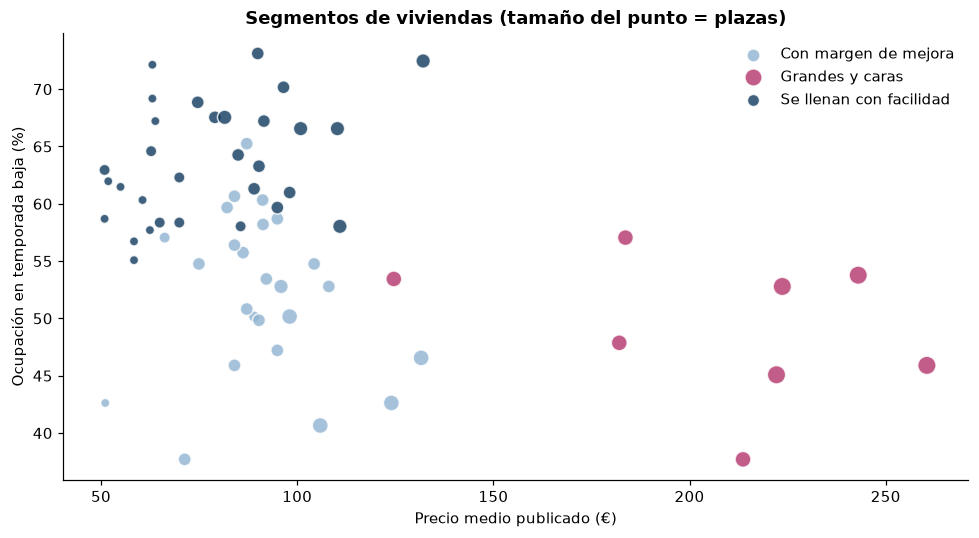

,viviendas,plazas,precio,ocup_alta,ocup_baja,antelacion
segmento,,,,,,
Grandes y caras,8,7.00,206.66,0.75,0.49,27.83
Se llenan con facilidad,31,3.32,77.95,0.80,0.64,32.29
Con margen de mejora,25,4.20,90.80,0.69,0.52,32.95


In [13]:
perfil = calendario.pivot_table(index="id_vivienda", columns="tarifa", values="ocupada").add_prefix("ocupacion_")
perfil["precio_medio"] = calendario.groupby("id_vivienda")["precio_noche"].mean()
perfil["antelacion_media"] = confirmadas.groupby("id_vivienda")["antelacion"].mean()
perfil = perfil.join(viviendas.set_index("id_vivienda")[["plazas", "tipo", "municipio"]])

columnas = ["ocupacion_alta", "ocupacion_baja", "precio_medio", "antelacion_media"]
X = StandardScaler().fit_transform(perfil[columnas])
modelo = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
perfil["segmento"] = modelo.labels_

resumen_seg = perfil.groupby("segmento").agg(
    viviendas=("plazas", "size"), plazas=("plazas", "mean"), precio=("precio_medio", "mean"),
    ocup_alta=("ocupacion_alta", "mean"), ocup_baja=("ocupacion_baja", "mean"),
    antelacion=("antelacion_media", "mean"))

# Nombres de los segmentos según sus características
nombres = {}
nombres[resumen_seg["precio"].idxmax()] = "Grandes y caras"
resto = resumen_seg.drop(resumen_seg["precio"].idxmax())
nombres[resto["ocup_alta"].idxmax()] = "Se llenan con facilidad"
nombres[resto["ocup_alta"].idxmin()] = "Con margen de mejora"
perfil["segmento_nombre"] = perfil["segmento"].map(nombres)
resumen_seg.index = resumen_seg.index.map(nombres)

fig, ax = plt.subplots(figsize=(9, 5))
colores_seg = {"Grandes y caras": ROSA, "Se llenan con facilidad": AZUL, "Con margen de mejora": AZUL_CLARO}
for nombre, grupo in perfil.groupby("segmento_nombre"):
    ax.scatter(grupo["precio_medio"], grupo["ocupacion_baja"] * 100, s=grupo["plazas"] * 18,
               color=colores_seg[nombre], alpha=0.8, label=nombre, edgecolor="white")
ax.set_xlabel("Precio medio publicado (€)")
ax.set_ylabel("Ocupación en temporada baja (%)")
ax.set_title("Segmentos de viviendas (tamaño del punto = plazas)")
ax.legend(frameon=False)
guardar("eda_08_segmentos.png")
resumen_seg

**Tres segmentos**
- **Se llenan con facilidad** (31 viviendas, sobre todo pequeñas): mucha ocupación todo el año. Su precio probablemente es bajo en temporada alta.
- **Con margen de mejora** (25 viviendas, de tamaño medio): ocupación más baja incluso en temporada alta, con precios algo más altos. Hay que revisar su precio y su anuncio.
- **Grandes y caras** (8 viviendas): villas y casas grandes que se vacían en temporada baja. Necesitan otro precio fuera del invierno.

## 12. Huéspedes, canales y reseñas

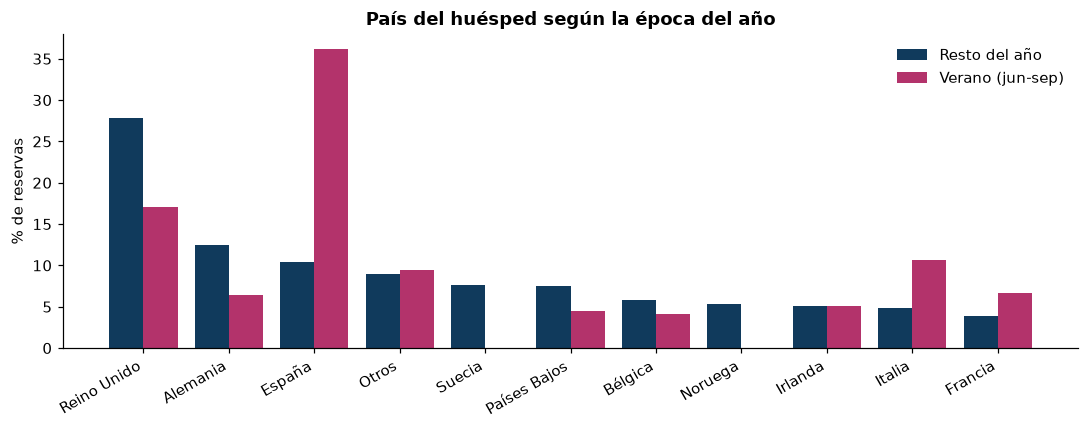

,reservas,cancelacion_pct,puntuacion,precio,cuota_%
canal,,,,,
Airbnb,2340,6.84,4.47,98.62,43.89
Booking,1787,6.60,4.46,98.96,33.52
Vrbo,461,7.16,4.40,98.22,8.65
Web,743,6.46,4.43,98.04,13.94


In [14]:
confirmadas["verano"] = np.where(confirmadas["mes"].isin([6, 7, 8, 9]), "Verano (jun-sep)", "Resto del año")
paises = pd.crosstab(confirmadas["pais_huesped"], confirmadas["verano"], normalize="columns") * 100
paises = paises.sort_values("Resto del año", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(paises))
ax.bar(x - 0.2, paises["Resto del año"], width=0.4, color=AZUL, label="Resto del año")
ax.bar(x + 0.2, paises["Verano (jun-sep)"], width=0.4, color=ROSA, label="Verano (jun-sep)")
ax.set_xticks(x, paises.index, rotation=30, ha="right")
ax.set_ylabel("% de reservas")
ax.set_title("País del huésped según la época del año")
ax.legend(frameon=False)
guardar("eda_09_paises.png")

canales = reservas.groupby("canal").agg(
    reservas=("id_reserva", "size"),
    cancelacion_pct=("estado", lambda s: (s == "cancelada").mean() * 100),
    puntuacion=("puntuacion", "mean"),
    precio=("precio_noche", "mean"))
canales["cuota_%"] = canales["reservas"] / canales["reservas"].sum() * 100
canales

In [15]:
# Reseñas según tamaño y tarifa
confirmadas.pivot_table(index="tamano", columns="tarifa", values="puntuacion", observed=True)[["alta", "media", "baja"]]

tarifa,alta,media,baja
tamano,,,
Pequeña (2-3),4.47,4.46,4.32
Mediana (4-5),4.41,4.50,4.52
Grande (6-8),4.51,4.55,4.29


**Qué vemos**
- En verano, los españoles pasan del 10 % al 36 % de las reservas y casi desaparecen los nórdicos. Los anuncios y los precios de verano deberían pensarse para otro tipo de cliente.
- Los canales se comportan de forma parecida: cancelaciones y puntuaciones similares. No es ahí donde está el problema.
- Las notas bajan un poco en temporada baja en las viviendas pequeñas y grandes. La diferencia es pequeña, así que no la tratamos como un problema principal.

## 13. Anomalías

In [16]:
# Meses de vivienda casi llenos o casi vacíos
vm["segmento"] = vm["id_vivienda"].map(perfil["segmento_nombre"])
print("Meses de vivienda con ocupación >= 95 %:", (vm["ocupacion"] >= 0.95).sum(), "de", len(vm))
print("Meses de vivienda con ocupación <= 30 %:", (vm["ocupacion"] <= 0.30).sum(), "de", len(vm))
print("\n% de meses casi vacíos (<= 30 %) por segmento:")
print((vm.assign(vacio=vm["ocupacion"] <= 0.30).groupby("segmento")["vacio"].mean() * 100).round(1))
print("\n% de meses casi llenos (>= 95 %) por segmento:")
print((vm.assign(lleno=vm["ocupacion"] >= 0.95).groupby("segmento")["lleno"].mean() * 100).round(1))

# Precios atípicos (método del rango intercuartílico)
q1, q3 = calendario["precio_noche"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = calendario[calendario["precio_noche"] > limite]
print(f"\nPrecios por encima de {limite:.0f} €: {len(atipicos)} días, todos de viviendas tipo:",
      atipicos["tipo"].unique())

# Estancia media: gestora frente al mercado
estancia_mercado = mercado[mercado["anio"] == 2025]["estancia_media"].mean()
estancia_gestora = confirmadas[confirmadas["fecha_entrada"].dt.year == 2025]["noches"].mean()
print(f"\nEstancia media 2025: gestora {estancia_gestora:.1f} noches, mercado {estancia_mercado:.1f} noches")

Meses de vivienda con ocupación >= 95 %: 133 de 1969
Meses de vivienda con ocupación <= 30 %: 106 de 1969

% de meses casi vacíos (<= 30 %) por segmento:
segmento
Con margen de mejora      8.20
Grandes y caras           6.10
Se llenan con facilidad   3.00
Name: vacio, dtype: float64

% de meses casi llenos (>= 95 %) por segmento:
segmento
Con margen de mejora      4.00
Grandes y caras           6.10
Se llenan con facilidad   9.10
Name: lleno, dtype: float64

Precios por encima de 158 €: 6270 días, todos de viviendas tipo: <StringArray>
['villa']
Length: 1, dtype: str

Estancia media 2025: gestora 8.3 noches, mercado 4.8 noches


**Anomalías encontradas**
- **Meses llenos y meses vacíos:** hay 133 meses de vivienda por encima del 95 % de ocupación (precio probablemente bajo) y 106 por debajo del 30 %. Los meses casi vacíos son más frecuentes en el segmento *con margen de mejora* (8 %) y en el de *grandes y caras* (6 %), y los casi llenos, en el de viviendas que *se llenan con facilidad* (9 %).
- **Precios atípicos:** los precios más altos son todos de villas; no son errores, sino otro tipo de producto. Por eso las analizamos como segmento aparte.
- **Estancia media:** las estancias de la gestora (unas 8 noches) duran casi el doble que la media del mercado (unas 5). Puede deberse al tipo de cliente de invierno que atrae, pero **también es un límite de nuestra simulación**, que conviene ajustar con la estancia real del ISTAC en la siguiente versión.
- **Datos reales:** la caída de 2020-2021 (COVID-19) y la bajada de oferta desde abril de 2026. Las cifras de Mogán cambian mucho porque tiene muy pocas viviendas.

## 14. Conclusiones

### Lo que el cliente cree y lo que muestran los datos

| El cliente cree | Los datos muestran |
|---|---|
| "Nuestro problema es la temporada baja; en invierno va todo bien." | En invierno también se pierde dinero: las fechas especiales se llenan al 95 % con casi dos meses de antelación **al precio de siempre**. |
| "Nuestras tres tarifas siguen las temporadas." | Según los datos reales del ISTAC, **abril** es más flojo de lo que se cobra y **agosto** y **octubre**, más fuertes. El calendario de tarifas está mal repartido. |
| "Estamos en línea con el mercado." | En **Adeje**, su zona principal, cada vivienda ingresa un **30 % menos** que la media del municipio. |
| "Con la nueva ley el mercado se complica." | Hay menos viviendas disponibles, pero los ingresos por vivienda del mercado **siguen subiendo**: hay margen para ajustar precios al alza. |

### Tres problemas u oportunidades

1. **Precios que no siguen a la demanda:** tres tarifas al año, mal repartidas, y el mismo precio en las fechas especiales. Se pierde dinero en los meses fuertes y se pierden reservas en los flojos.
2. **Viviendas grandes vacías en temporada baja:** por debajo del 50 % de ocupación con precios de más de 200 €.
3. **Adeje por debajo del mercado:** un 30 % menos de ingresos por vivienda en la zona con más viviendas de la gestora, con riesgo de que los propietarios se vayan a otra gestora.

### Problema seleccionado

**El precio no se adapta a la demanda** (problema 1). Incluye en parte los otros dos: las viviendas grandes y Adeje son casos concretos de precios mal ajustados.

### Traducción a ciencia de datos

| | |
|---|---|
| **Problema empresarial** | Perdemos ingresos porque ponemos el mismo precio en momentos con demanda muy distinta. |
| **Problema de datos** | Predecir la **ocupación esperada** de cada vivienda en cada mes (y en las fechas especiales) según su precio, sus características, la época y la demanda del mercado, y recomendar el **precio que maximiza los ingresos esperados** (precio × ocupación). |
| **Tipo de problema** | Aprendizaje supervisado (regresión o clasificación de si una noche se reserva) más una optimización sencilla del precio. |
| **Datos** | `calendario_precios` (variable objetivo: `ocupada`), `viviendas`, `reservas` (antelación) y `mercado_istac` (demanda real por municipio y mes). |
| **Cómo mediremos si funciona** | Error de la predicción de ocupación en meses que el modelo no ha visto (2026) e ingresos esperados con el precio recomendado frente al precio actual. |
| **Limitación** | La gestora casi no ha cambiado sus precios, así que el efecto del precio se mide con poca precisión. Propuesta: aplicar los cambios de forma gradual y medir el resultado (por ejemplo, subir el precio en la mitad de las viviendas pequeñas en Carnaval y comparar). |

In [17]:
con.close()